## Imports

In [2]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from collections import Counter
import sys
from pathlib import Path
from types import SimpleNamespace
import matplotlib.colors as mcolors
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
from scipy.stats import gaussian_kde
import math
from matplotlib.backends.backend_pdf import PdfPages

# Add the parent of mixture_density_network to sys.path
project_root = Path().absolute().parent  # points to Madidi_forest_analysis
sys.path.append(str(project_root))
print("Added to sys.path:", project_root)
from mixture_density_network.src.blocks import MixtureDensityNetwork, NoiseType
from mixture_density_network.training.train import LitModel

Added to sys.path: /stor/work/Wilke/kelly/Madidi_forest_analysis
starting imports
finished imports


## Device Configuration

In [3]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
device

device(type='cpu')

## Load Data and Model

In [4]:
interests = ["DrySeasonDeficit", "ResinPi", "TotalP"]
components = [1, 2, 3, 4, 5, 10, 15, 20]
base_template = "batch32_epochs100_lr0.0004_weightdecay1e-06_beta10.9_beta20.95_dropout0.1_numcomponents{num_components}_hidden64_rarity4"

example_name = base_template.format(num_components=1)
parts = example_name.split("_")

# Extract parameters
params = {}
for part in parts:
    if part.startswith("batch"):
        params["batch_size"] = int(part.replace("batch", ""))
    elif part.startswith("epochs"):
        params["epochs"] = int(part.replace("epochs", ""))
    elif part.startswith("lr"):
        params["learn_rate"] = float(part.replace("lr", ""))
    elif part.startswith("weightdecay"):
        params["weight_decay"] = float(part.replace("weightdecay", ""))
    elif part.startswith("beta1"):
        params["beta1"] = float(part.replace("beta1", ""))
    elif part.startswith("beta2"):
        params["beta2"] = float(part.replace("beta2", ""))
    elif part.startswith("dropout"):
        params["dropout"] = float(part.replace("dropout", ""))
    elif part.startswith("hidden"):
        params["hidden_size"] = int(part.replace("hidden", ""))
    elif part.startswith("rarity"):
        params["rarity_threshold"] = int(part.replace("rarity", ""))
        
# Default rarity_threshold to None if not found
params["rarity_threshold"] = params.get("rarity_threshold", None)

print(params)

{'batch_size': 32, 'epochs': 100, 'learn_rate': 0.0004, 'weight_decay': 1e-06, 'beta1': 0.9, 'beta2': 0.95, 'dropout': 0.1, 'hidden_size': 64, 'rarity_threshold': 4}


In [5]:
interests_data = {}
log_interests = {"ResinPi", "TotalP"}

for interest in interests:    

    interests_data.setdefault(interest, {})

    use_log = interest in log_interests
    print(f"{interest}: using {'log' if use_log else 'raw'} data")

    for num_comp in components:

        # Build directory name conditionally
        base_dir_name = base_template.format(num_components=num_comp)
        current_dir_name = base_dir_name + ("_log" if use_log else "")

        # Define directories
        data_dir = Path(f"../output/Panama/{interest}/{current_dir_name}")
        output_dir = Path(f"figures/Panama/{interest}/{current_dir_name}")

        # Pick the checkpoint with the lowest validation loss
        checkpoint_files = list((data_dir / "checkpoints").glob("checkpoint_epoch=*_val_loss=*.ckpt"))
        best_checkpoint = min(checkpoint_files, key=lambda p: float(p.name.split("val_loss=")[-1].replace(".ckpt", "").split("_")[0]))

        # Extract best epoch 
        best_epoch = int(best_checkpoint.name.split("checkpoint_epoch=")[-1].split("_")[0])
        print(f"Best epoch for {interest}: {best_epoch}")

        # Load dataset
        rarity_suffix = f"_rarity{params['rarity_threshold']}" if params["rarity_threshold"] else ""
        if use_log:
            dataset_path = Path(f"../data/metadata/panama/dataset_{interest}{rarity_suffix}_log.pt")
        else:
            dataset_path = Path(f"../data/metadata/panama/dataset_{interest}{rarity_suffix}.pt")
        dataset = torch.load(dataset_path)
        X_train = dataset["train"]["embedding"].to(device)
        y_train = dataset["train"][interest].to(device)
        X_val = dataset["val"]["embedding"].to(device)
        y_val = dataset["val"][interest].to(device)
        X_test = dataset["test"]["embedding"].to(device)
        y_test = dataset["test"][interest].to(device)

        # Build train/test DataFrames 
        train_df = pd.DataFrame({
            'FEATURE_ID': dataset['train']['FEATURE_ID'],
            interest: dataset['train'][interest].cpu().numpy(),
            'embedding': list(dataset['train']['embedding'].cpu().numpy())
        })

        test_df = pd.DataFrame({
            'FEATURE_ID': dataset['test']['FEATURE_ID'],
            interest: dataset['test'][interest].cpu().numpy(),
            'embedding': list(dataset['test']['embedding'].cpu().numpy())
        })

        # Load model
        args = SimpleNamespace(
            data_file=str(dataset_path),
            lr=params["learn_rate"],
            weight_decay=params["weight_decay"],
            batch_size=params["batch_size"],
            epochs=params["epochs"],
            beta1=params["beta1"],
            beta2=params["beta2"],
            dropout=params["dropout"],
            num_components=num_comp,
            hidden_dim=params["hidden_size"],
        )
        model_module = LitModel.load_from_checkpoint(checkpoint_path=str(best_checkpoint), args=args, map_location=device,)
        model = model_module.model.to(device)
        model.eval()

        # Generate predictions
        with torch.no_grad():
            y_hat = model.sample(X_test)

        y_mean = torch.tensor(train_df[interest].values, dtype=torch.float32).mean().item()
        y_std = torch.tensor(train_df[interest].values, dtype=torch.float32).std().item()
        y_hat_unnormalized = y_hat * y_std + y_mean

        y_test_unsq = y_test.unsqueeze(1)

        # Rarity distribution
        all_splits = []
        for split in ['train', 'val', 'test']:
            df_split = pd.DataFrame({'FEATURE_ID': dataset[split]['FEATURE_ID'].numpy()})
            all_splits.append(df_split)
        all_df = pd.concat(all_splits, ignore_index=True)
        feature_counts = all_df['FEATURE_ID'].value_counts().reset_index()
        feature_counts.columns = ['FEATURE_ID', 'num_plots']
        rarity_threshold = 4
        feature_counts['rarity'] = ['Rare' if n <= rarity_threshold else 'Majority' for n in feature_counts['num_plots']]

        # Store everything
        interests_data[interest][num_comp] = {
            "dataset": dataset,
            "best_epoch": best_epoch,
            "train_df": train_df,
            "test_df": test_df,
            "X_test": X_test,
            "y_test": y_test_unsq,
            "y_hat": y_hat_unnormalized,
            "feature_counts": feature_counts,
            "output_dir": output_dir,
        }

DrySeasonDeficit: using raw data
Best epoch for DrySeasonDeficit: 2
Best epoch for DrySeasonDeficit: 2
Best epoch for DrySeasonDeficit: 3
Best epoch for DrySeasonDeficit: 5
Best epoch for DrySeasonDeficit: 9
Best epoch for DrySeasonDeficit: 23
Best epoch for DrySeasonDeficit: 28
Best epoch for DrySeasonDeficit: 27
ResinPi: using log data
Best epoch for ResinPi: 2
Best epoch for ResinPi: 2
Best epoch for ResinPi: 6
Best epoch for ResinPi: 3
Best epoch for ResinPi: 9
Best epoch for ResinPi: 24
Best epoch for ResinPi: 36
Best epoch for ResinPi: 55
TotalP: using log data
Best epoch for TotalP: 3
Best epoch for TotalP: 3
Best epoch for TotalP: 6
Best epoch for TotalP: 9
Best epoch for TotalP: 7
Best epoch for TotalP: 10
Best epoch for TotalP: 12
Best epoch for TotalP: 7


In [6]:
normal_names = {
    "DrySeasonDeficit": "Dry-Season Moisture",
    "ResinPi": "Log Resin Phosphorus",
    "TotalP": "Log Total Phosphorus",
}

In [7]:
def darken_color(color, amount=0.4):
    """
    Darken the given color by multiplying (1-luminosity) by amount
    """
    c = mcolors.to_rgb(color)
    return tuple(max(min(comp * amount, 1), 0)for comp in c)

## Plot Loss

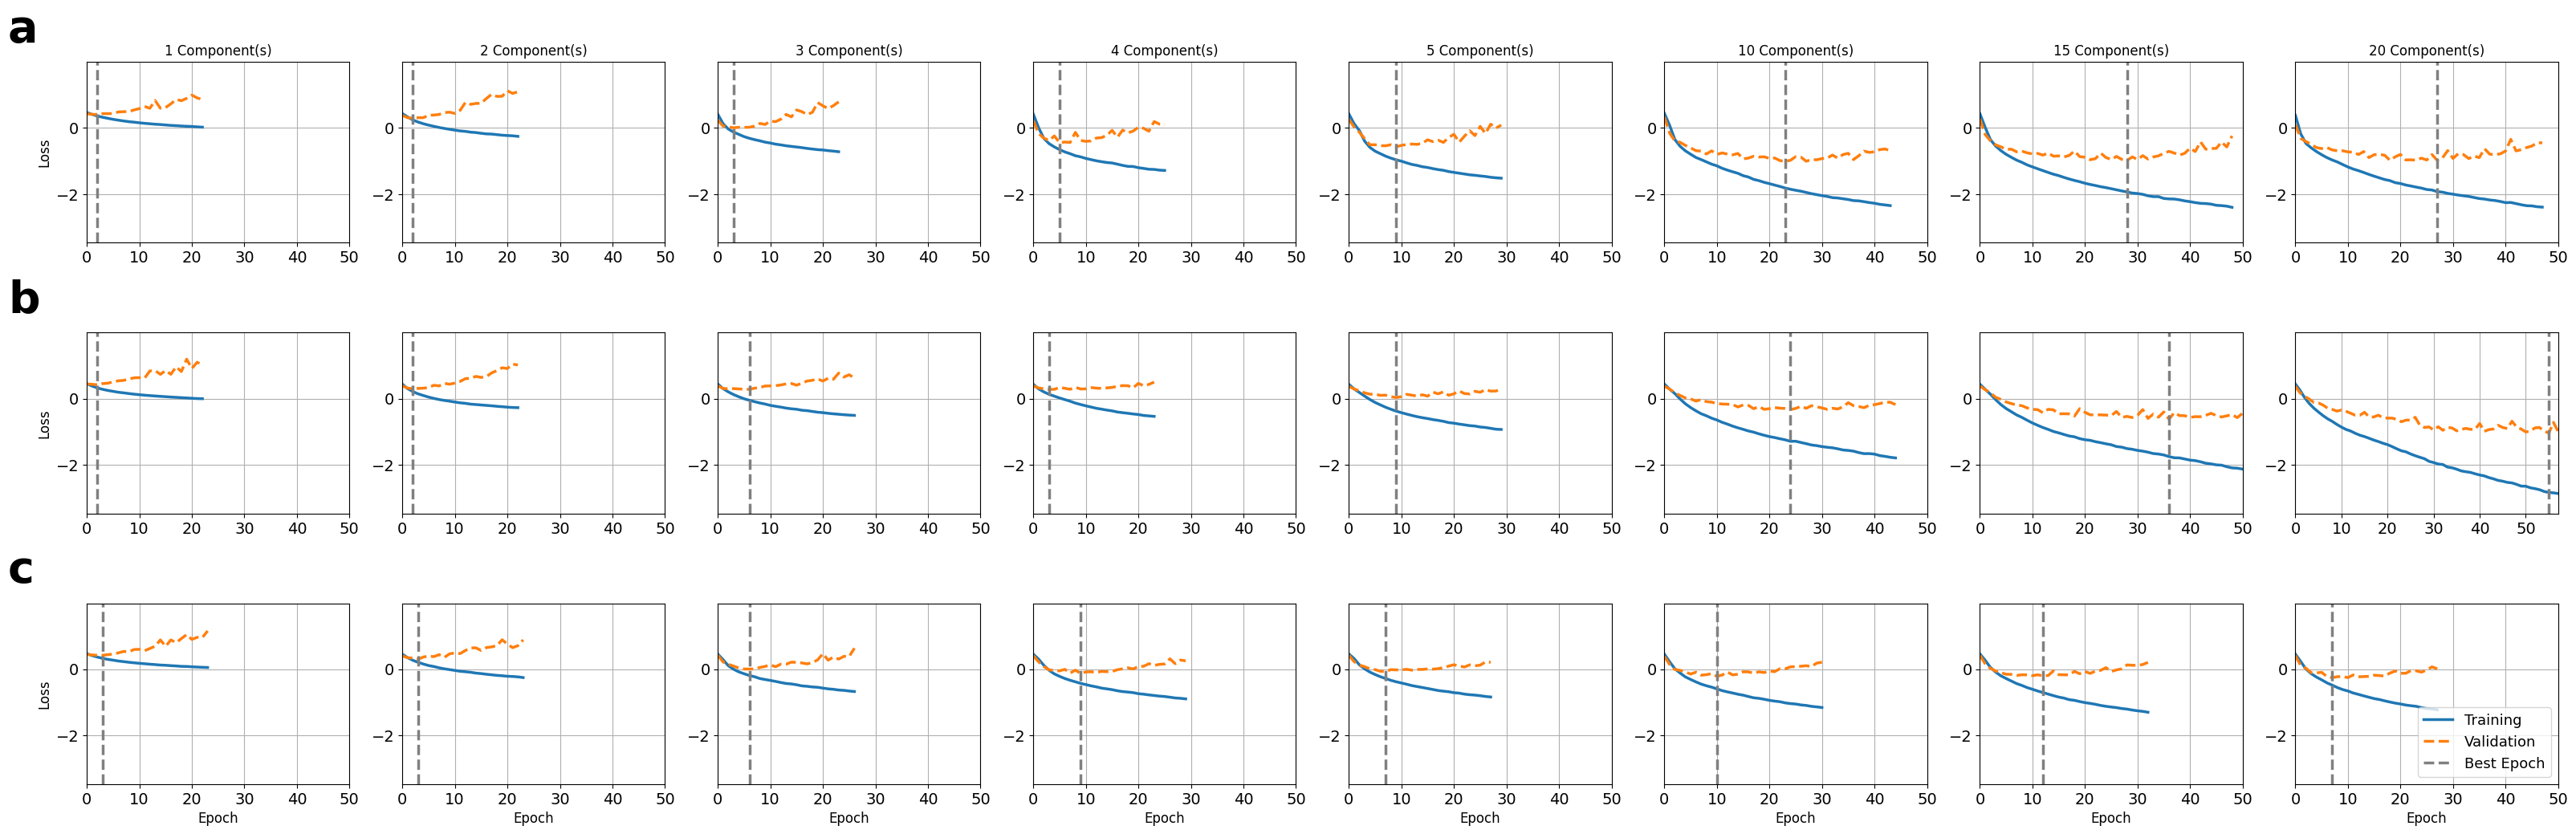

In [8]:
num_rows = len(interests)
num_cols = len(components)

fig, axes = plt.subplots(num_rows, num_cols, figsize=(4 * num_cols, 3.5 * num_rows))
labels = ['a', 'b', 'c']
all_axes = axes.flatten()

# Gather all y-limits across all subplots
global_y_min = float("inf")
global_y_max = float("-inf")
# Compute y-limits for all data that exists
for interest in interests:
    use_log = interest in log_interests
    for num_comp in components:
        base_dir_name = base_template.format(num_components=num_comp)
        current_dir_name = base_dir_name + ("_log" if use_log else "")
        data_dir = Path(f"../output/Panama/{interest}/{current_dir_name}")
        if not data_dir.exists():
            continue
        metrics_csv = data_dir / "training/version_0/metrics.csv"
        metrics = pd.read_csv(metrics_csv)
        train_losses = metrics[['epoch', 'train_loss']].dropna()
        val_losses = metrics[['epoch', 'val_loss']].dropna()
        global_y_min = min(global_y_min, train_losses['train_loss'].min(), val_losses['val_loss'].min())
        global_y_max = max(global_y_max, train_losses['train_loss'].max(), val_losses['val_loss'].max())
# Add padding
y_buffer = 0.8
global_y_max += y_buffer

for row_idx, interest in enumerate(interests):
    use_log = interest in log_interests
    label = labels[row_idx]

    for col_idx, num_comp in enumerate(components):
        ax = axes[row_idx, col_idx]

        # Build base folder name
        base_dir_name = base_template.format(num_components=num_comp)
        current_dir_name = base_dir_name + ("_log" if use_log else "")

        # Full path
        data_dir = Path(f"../output/Panama/{interest}/{current_dir_name}")

        # If folder does not exist, skip
        if not data_dir.exists():
            print(f"Missing folder: {interest}, comp={num_comp}")
            ax.axis("off")
            continue

        metrics_csv = data_dir / "training/version_0/metrics.csv"
        metrics = pd.read_csv(metrics_csv)

        train_losses = metrics[['epoch', 'train_loss']].dropna().sort_values('epoch')
        val_losses = metrics[['epoch', 'val_loss']].dropna().sort_values('epoch')

        epochs = train_losses['epoch'].values
        ax.plot(epochs, train_losses['train_loss'], label='Training', color='tab:blue', linewidth=2.5)
        ax.plot(epochs, val_losses['val_loss'], label='Validation', color='tab:orange', linestyle='--', linewidth=2.5)

        ax.tick_params(labelsize=14)
        ax.grid(True)

        # Add vertical line at best epoch
        best_epoch_idx = val_losses['val_loss'].idxmin()
        best_epoch = int(val_losses.loc[best_epoch_idx, 'epoch'])
        ax.axvline(best_epoch, color='gray', linestyle='--', label='Best Epoch', linewidth=2.5)

        # Set x-axis a bit beyond the best checkpoint epoch
        buffer = 2
        ax.set_xlim(left=0, right=best_epoch + buffer)

        ax.set_ylim(global_y_min, global_y_max)

        # Titles (top row)
        if row_idx == 0:
            ax.set_title(f"{num_comp} Component(s)", fontsize=12)

        # Y labels (left column)
        if col_idx == 0:
            ax.set_ylabel("Loss", fontsize=12)

        # X labels (bottom row)
        if row_idx == num_rows - 1:
            ax.set_xlabel("Epoch", fontsize=12)
            
        # Only show legend on the last subplot
        if ax == all_axes[-1]:
            ax.legend(fontsize=13, loc='lower right')

# Define consistent x-ticks starting at 0
x_min = 0
all_axes = axes.flatten()
x_max = max(ax.get_xlim()[1] for ax in all_axes if ax.has_data())
x_ticks = np.arange(x_min, x_max + 1, step=10)  
for ax in all_axes:
    if ax.has_data():
        ax.set_xticks(x_ticks)

# Add row letters (a, b, c) on the left of each row
row_letters = ["a", "b", "c"]
for row, letter in enumerate(row_letters):
    ax = axes[row, 0]  # first column
    ax.annotate(f"{letter}", xy=(-0.3, 1.06), xycoords='axes fraction', fontsize=40, fontweight='bold', va='bottom', ha='left')

plt.tight_layout()  
plt.savefig("figures/Panama/final/combined_loss_components_comparison_rarity.pdf", dpi=300)
plt.show()

## Plot Distribution

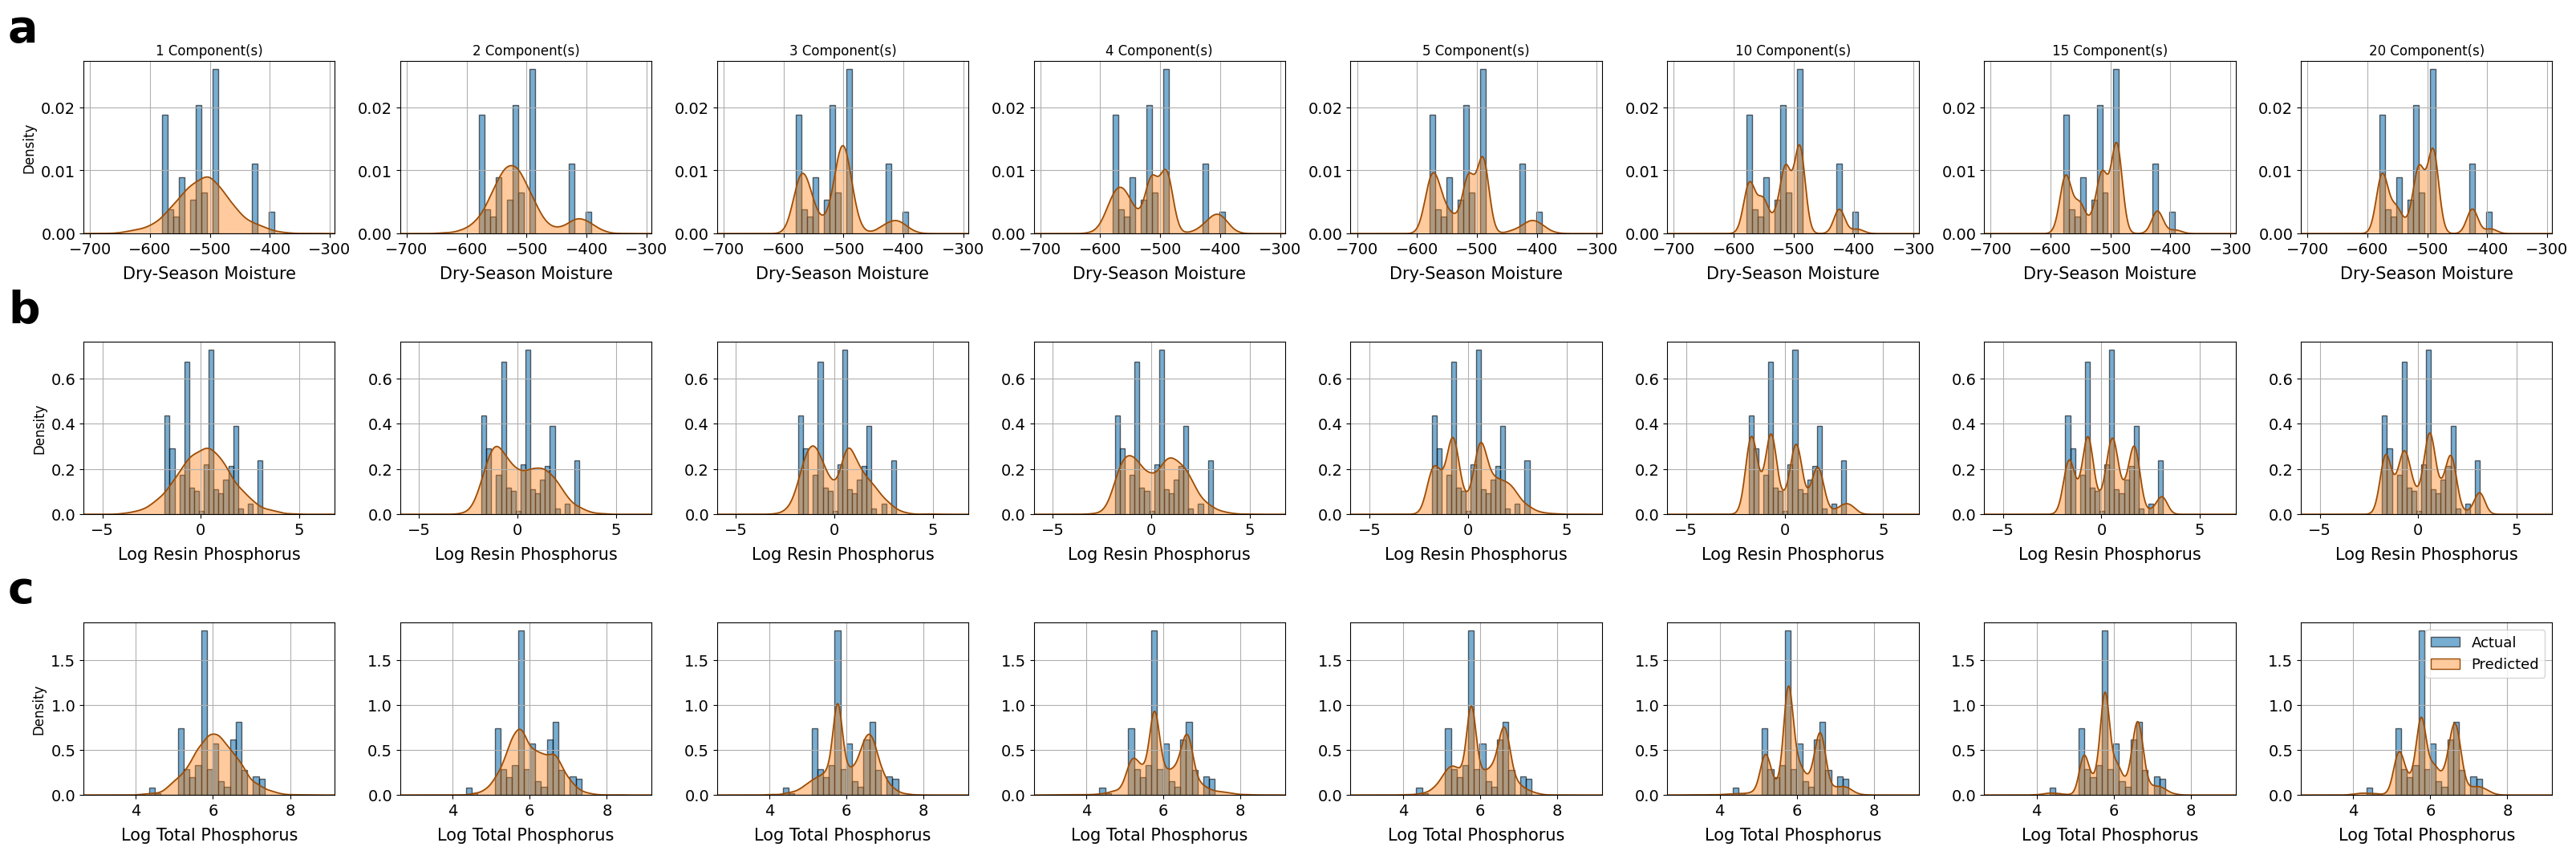

In [10]:
## Plot Distribution
num_rows = len(interests)
num_cols = len(components)

fig, axes = plt.subplots(
    num_rows,
    num_cols,
    figsize=(4 * num_cols, 3.5 * num_rows),
    constrained_layout=True
)

row_letters = ["a", "b", "c"]

for row_idx, interest in enumerate(interests):

    # Consistent x-limits across all component counts for this interest
    all_actual = []
    all_predicted = []

    for num_comp in components:
        data = interests_data[interest][num_comp]

        all_actual.append(data["y_test"][:, 0].cpu().numpy())
        all_predicted.append(data["y_hat"][:, 0].cpu().numpy())

    xmin = min(np.min(x) for x in all_actual + all_predicted)
    xmax = max(np.max(x) for x in all_actual + all_predicted)
    margin = (xmax - xmin) * 0.05

    for col_idx, num_comp in enumerate(components):

        ax = axes[row_idx, col_idx]
        data = interests_data[interest][num_comp]

        actual = data["y_test"][:, 0].cpu().numpy()
        predicted = data["y_hat"][:, 0].cpu().numpy()

        # Histogram
        ax.hist(
            actual,
            bins=20,
            density=True,
            alpha=0.6,
            color="tab:blue",
            edgecolor="black",
            label="Actual"
        )

        # KDE
        kde = gaussian_kde(predicted)
        x_vals = np.linspace(xmin - margin, xmax + margin, 500)
        kde_vals = kde(x_vals)

        ax.fill_between(
            x_vals,
            kde_vals,
            color=mcolors.to_rgba("tab:orange", 0.4)
        )

        ax.plot(
            x_vals,
            kde_vals,
            color=darken_color("tab:orange", amount=0.6),
            linewidth=1.25
        )

        ax.set_xlim(xmin - margin, xmax + margin)
        ax.grid(True)
        ax.tick_params(axis="both", labelsize=14)
        ax.set_xlabel(normal_names.get(interest, interest), fontsize=15, labelpad=8)

        if row_idx == 0:
            ax.set_title(f"{num_comp} Component(s)", fontsize=12)

        if col_idx == 0:
            ax.set_ylabel("Density", fontsize=12)
            
        # Only show legend once
        if row_idx == num_rows - 1 and col_idx == num_cols - 1:
            kde_proxy = mpatches.Patch(
                facecolor=mcolors.to_rgba("tab:orange", 0.4),
                edgecolor=darken_color("tab:orange", amount=0.6),
                label="Predicted"
            )
            handles, labels = ax.get_legend_handles_labels()
            handles.append(kde_proxy)
            ax.legend(handles=handles, fontsize=13, loc="upper right")

    axes[row_idx, 0].annotate(
        row_letters[row_idx],
        xy=(-0.3, 1.06),
        xycoords="axes fraction",
        fontsize=40,
        fontweight="bold",
        va="bottom",
        ha="left"
    )

plt.savefig(
    "figures/Panama/final/combined_distribution_components_comparison_rarity.pdf",
    dpi=300,
    bbox_inches="tight"
)
plt.show()